# Employee Attrition Prediction

Employee turnover is a major challenge for organizations, as losing employees can increase recruitment costs and affect overall productivity. Understanding the factors associated with employee attrition can help organizations identify potential risks and make better retention decisions.

In this project, exploratory data analysis was performed to identify patterns and factors related to employee attrition. A Logistic Regression model was developed to predict whether an employee is likely to leave the company based on different personal, job-related, and satisfaction features.

Logistic Regression was selected as the main model due to its interpretability, allowing better understanding of how different factors influence the likelihood of employee attrition.

## Project Objective

The main objective is to analyze employee characteristics and build a classification model that predicts employee attrition while identifying the key factors associated with turnover.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("data/IBM Data.csv")


# 1) Data Understanding


In [2]:
df.shape

(1470, 35)

In [3]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [4]:
df.describe(include = "all")


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470,1470,1470.000000,1470,1470.000000,1470.000000,1470,1470.0,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
unique,NaN,2,3,NaN,3,NaN,NaN,6,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,No,Travel_Rarely,NaN,Research & Development,NaN,NaN,Life Sciences,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1233,1043,NaN,961,NaN,NaN,606,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,36.923810,NaN,NaN,802.485714,NaN,9.192517,2.912925,NaN,1.0,1024.865306,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,NaN,NaN,403.509100,NaN,8.106864,1.024165,NaN,0.0,602.024335,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,NaN,NaN,102.000000,NaN,1.000000,1.000000,NaN,1.0,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,NaN,NaN,465.000000,NaN,2.000000,2.000000,NaN,1.0,491.250000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,NaN,NaN,802.000000,NaN,7.000000,3.000000,NaN,1.0,1020.500000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,NaN,NaN,1157.000000,NaN,14.000000,4.000000,NaN,1.0,1555.750000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [6]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# 2) Data Cleaning


In [7]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Attrition"]=df["Attrition"].map({"No": 0,"Yes": 1})

In [10]:
X = df.drop(columns=["Attrition"]).copy()

X = pd.get_dummies(X, drop_first=True, dtype=int)

X = X.select_dtypes(include="number")
X = X.loc[:, X.nunique() > 1]

from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame({
    "Feature": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

display(vif_data.sort_values("VIF", ascending=False))

,Feature,VIF
26,Department_Research & Development,44.054049
27,Department_Sales,43.959087
28,EducationField_Life Sciences,24.119349
30,EducationField_Medical,21.671938
10,MonthlyIncome,18.152179
40,JobRole_Sales Executive,14.699119
8,JobLevel,14.157614
29,EducationField_Marketing,10.896101
32,EducationField_Technical Degree,8.874596
34,JobRole_Human Resources,7.255492


In [11]:
from sklearn.preprocessing import OneHotEncoder

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

encoded = encoder.fit_transform(df[categorical_cols])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=df.index
)

df = df.drop(columns=categorical_cols)
df = pd.concat([df, encoded_df], axis=1)

/var/folders/wc/vn6dzgy15mjfz5q2f7hysdkr0000gn/T/ipykernel_27245/3723294938.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


In [12]:
df = df.drop(columns=["EmployeeCount","StandardHours","EmployeeNumber"])


# Exploratory Data Analysis (EDA)


In [13]:
for prefix in [
    "Gender",
    "Department",
    "BusinessTravel",
    "OverTime",
    "MaritalStatus",
    "EducationField",
    "JobRole"
]:
    cols = [c for c in X.columns if c.startswith(prefix + "_")]
    print(f"\n{prefix}: {cols}")


Gender: ['Gender_Male']

Department: ['Department_Research & Development', 'Department_Sales']

BusinessTravel: ['BusinessTravel_Travel_Frequently', 'BusinessTravel_Travel_Rarely']

OverTime: ['OverTime_Yes']

MaritalStatus: ['MaritalStatus_Married', 'MaritalStatus_Single']

EducationField: ['EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree']

JobRole: ['JobRole_Human Resources', 'JobRole_Laboratory Technician', 'JobRole_Manager', 'JobRole_Manufacturing Director', 'JobRole_Research Director', 'JobRole_Research Scientist', 'JobRole_Sales Executive', 'JobRole_Sales Representative']


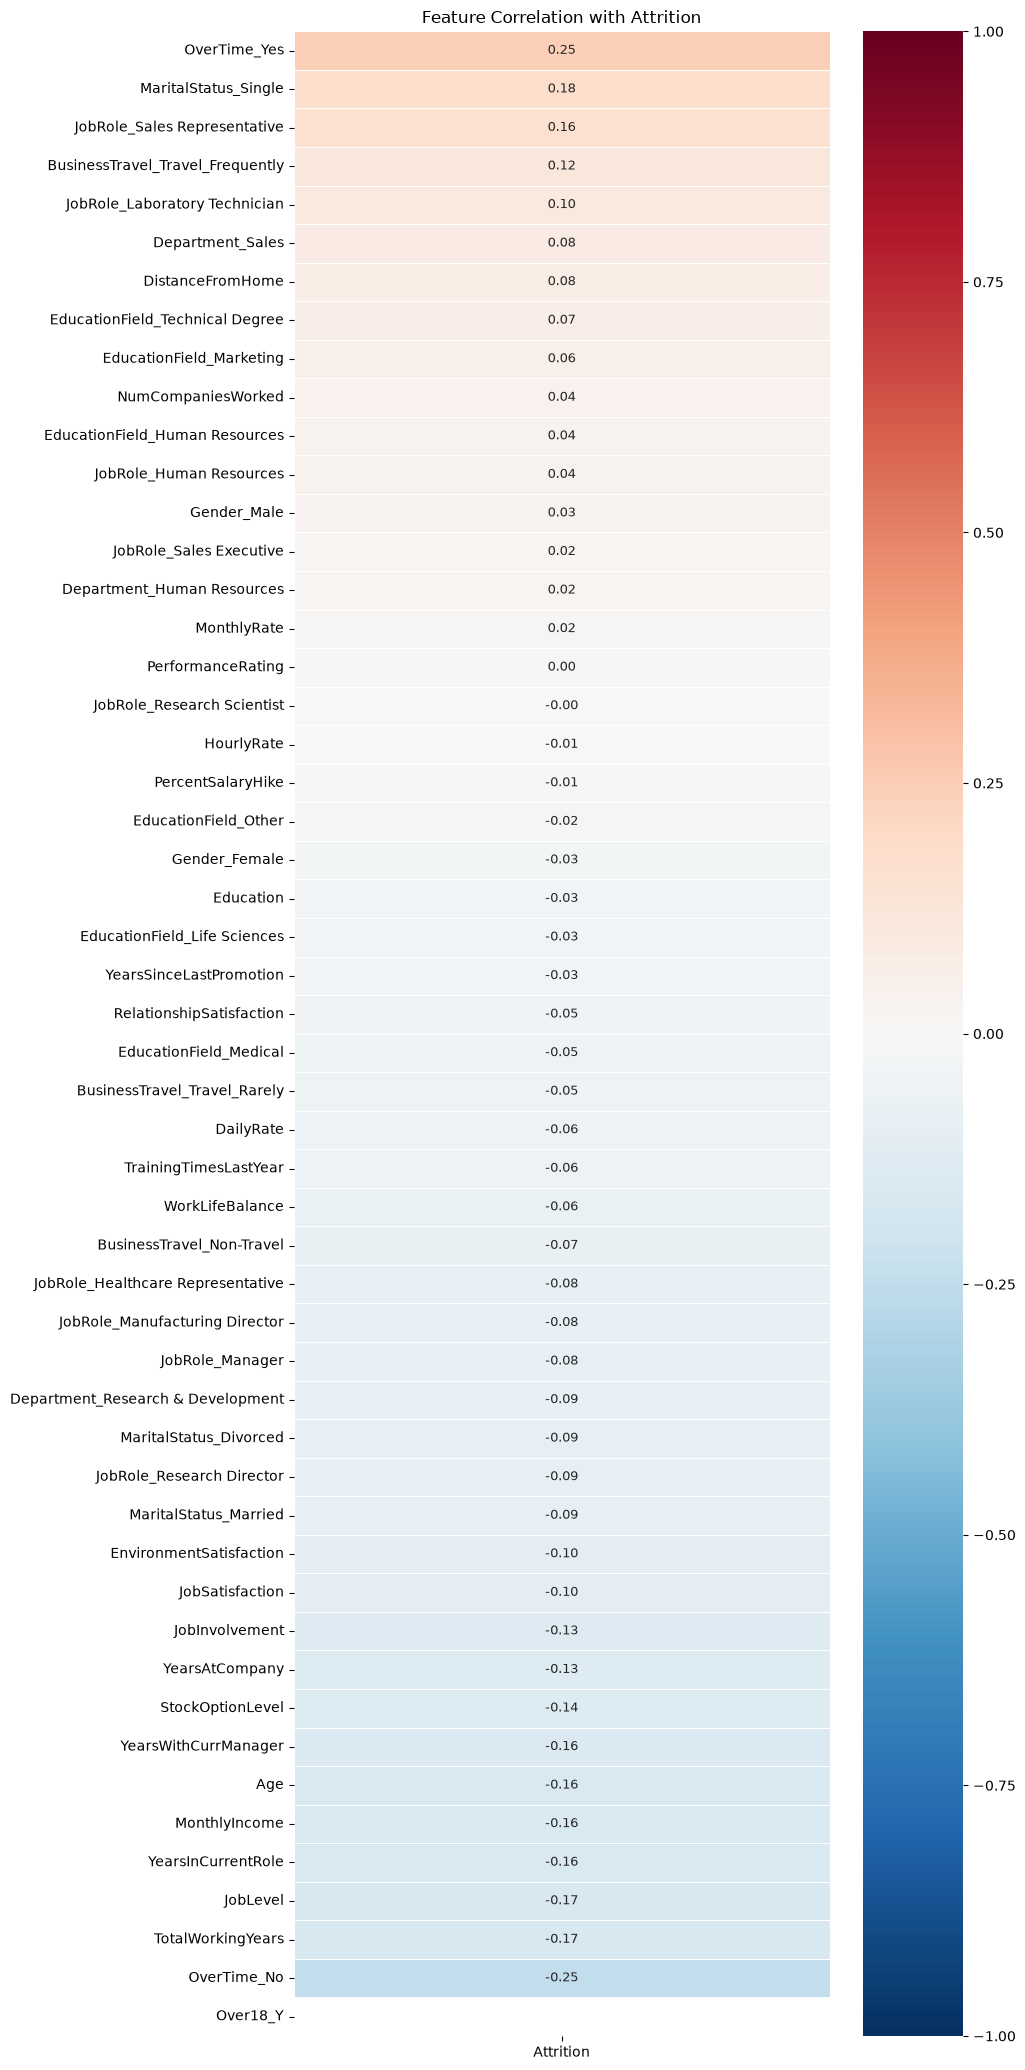

In [14]:
corr = (
    df.corr(numeric_only=True)["Attrition"]
    .drop("Attrition")
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, max(12, len(corr) * 0.4)))

sns.heatmap(
    corr.to_frame(),
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 9}
)

plt.title("Feature Correlation with Attrition")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

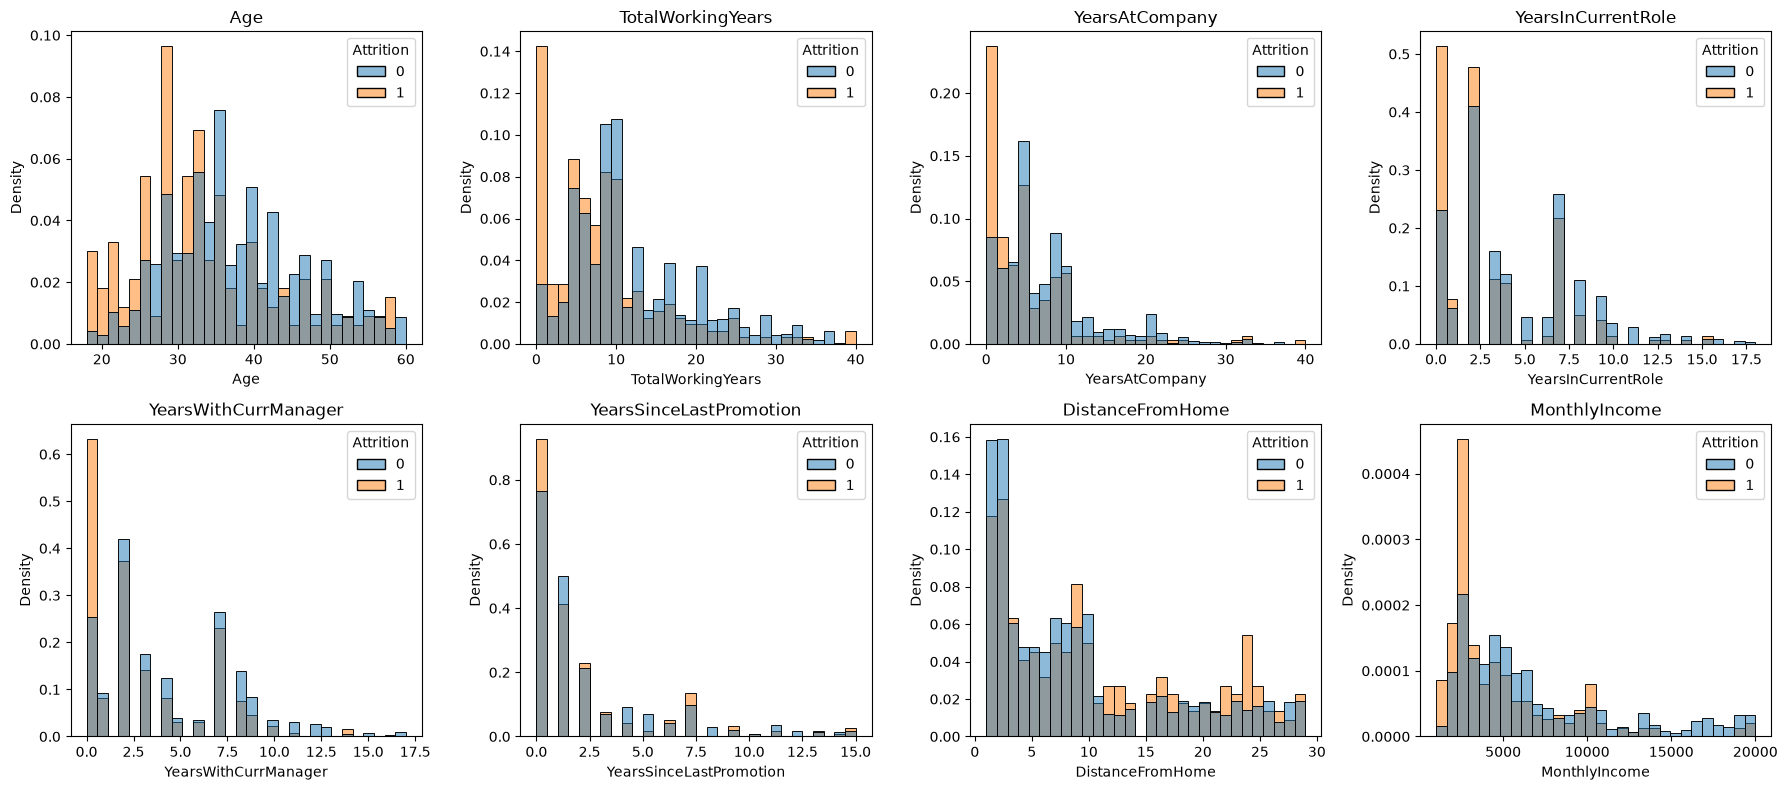

In [15]:
cols = [
    "Age",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsWithCurrManager",
    "YearsSinceLastPromotion",
    "DistanceFromHome",
    "MonthlyIncome"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, cols):
    sns.histplot(
        data=df,
        x=col,
        hue="Attrition",
        bins=30,
        multiple="layer",
        stat="density",
        common_norm=False,
        ax=ax)
    ax.set_title(col)



plt.tight_layout()
plt.show()

### Observations

* Employees who left the company are more concentrated in the **lowest tenure values** across most experience-related features, although departures still occur at higher tenure levels.
* A noticeable peak is also observed around a **monthly income of approximately 2,500**, which may indicate a pattern worth further investigation.
* **DistanceFromHome** does not show a clear pattern that distinguishes employees who left from those who stayed.


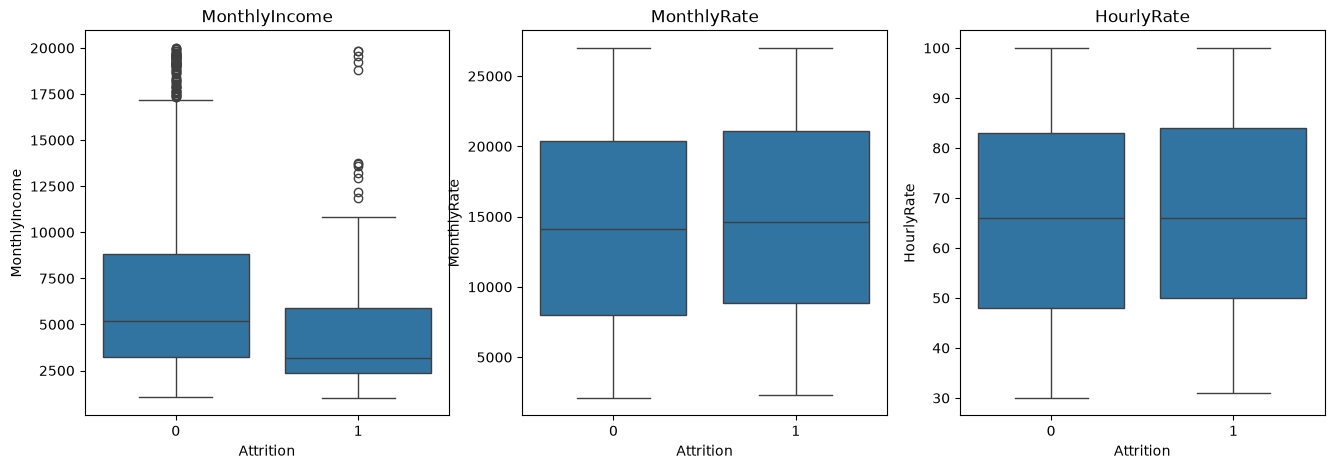

In [16]:
cols = ["MonthlyIncome", "MonthlyRate", "HourlyRate"]
fig,axes=plt.subplots(1,3,figsize=(16,5))

for ax, col in zip(axes, cols):
    sns.boxplot(
        data=df,
        x="Attrition",
        y=col,
        ax=ax)
    ax.set_title(col)
plt.show()

### Salary Analysis

Monthly Income showed a clearer difference between employees who left and stayed compared to Monthly Rate and Hourly Rate, indicating that income level may have a stronger association with employee attrition.

travel_marital_attrition=(
    df.groupby(["BusinessTravel", "MaritalStatus"])["Attrition"]
    .mean()
    .mul(100)
    .reset_index())

plt.figure(figsize=(9,5))

sns.barplot(
    data=travel_marital_attrition,
    x="BusinessTravel",
    y="Attrition",
    hue="MaritalStatus",
    palette="Blues")

plt.title("Attrition Rate by Business Travel and Marital Status")
plt.xlabel("Business Travel")
plt.ylabel("Attrition Rate")

plt.show()

### Additional Attrition Factors

Single employees had the highest attrition rate despite not being the largest group. In addition, frequent business travelers showed higher attrition rates, suggesting a possible relationship between these factors and employee turnover.

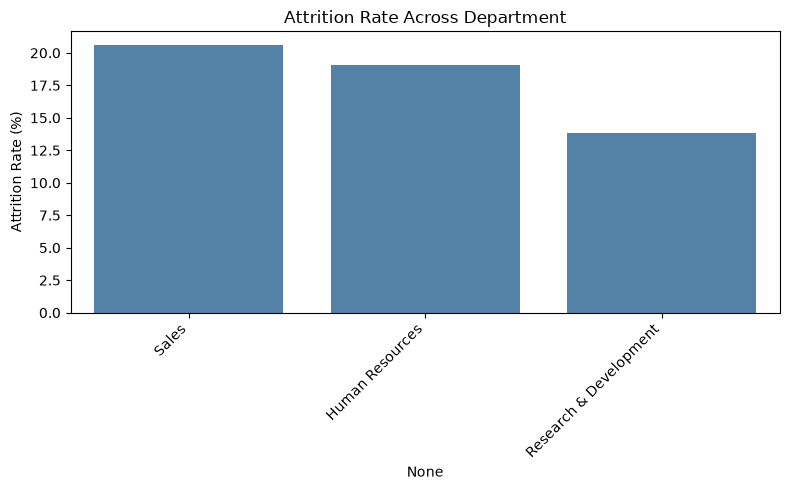

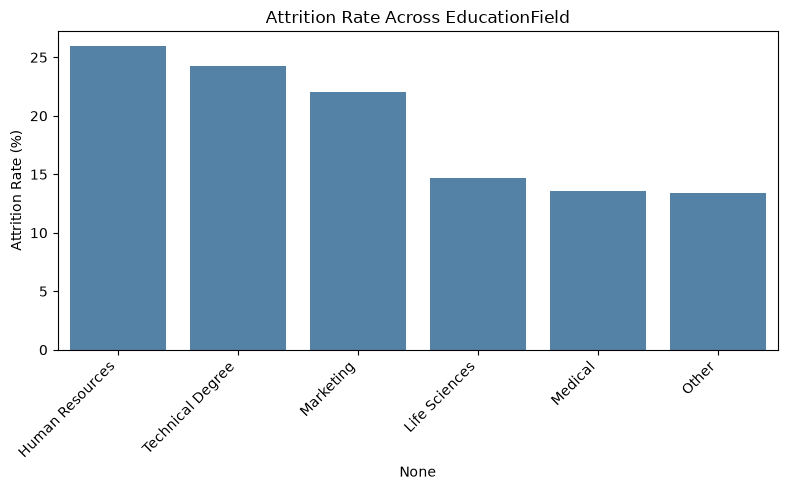

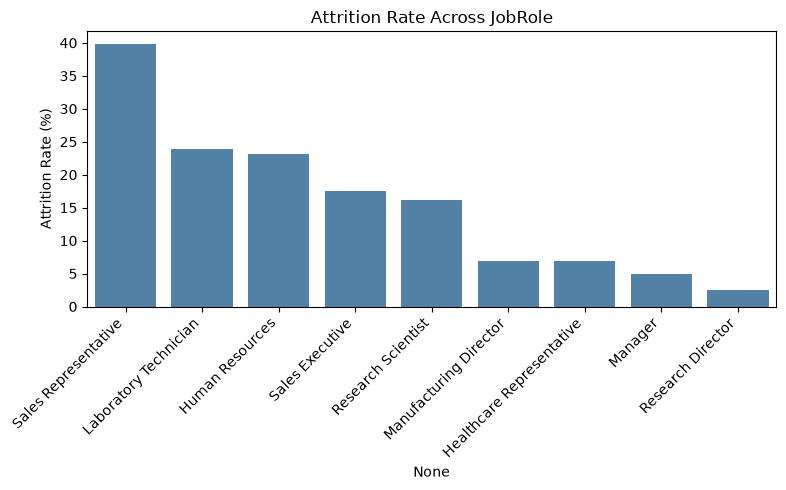

In [17]:
cat_cols = ["Department", "EducationField", "JobRole"]

for col in cat_cols:
    cols = [c for c in df.columns if c.startswith(col + "_")]
    rate = {
        c.replace(col + "_", ""): df.loc[df[c] == 1, "Attrition"].mean() * 100
        for c in cols}

    rate = pd.Series(rate).sort_values(ascending=False)

    plt.figure(figsize=(8, 5))
    sns.barplot(x=rate.index, y=rate.values, color="steelblue")
    plt.title(f"Attrition Rate Across {col}")
    plt.ylabel("Attrition Rate (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### Department Composition

The **Research & Development** department has a more diverse mix of job roles, including roles with relatively lower attrition rates. Additionally, employees in higher job levels, such as managers and directors, generally showed lower attrition, which may influence the overall attrition pattern across departments. Other departments are more concentrated in fewer job roles, some of which show higher attrition rates. For **Human Resources**, the noticeable income gap between employees who stayed and those who left may also be worth further investigation.

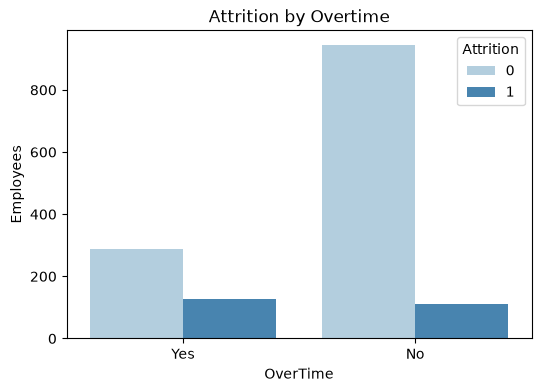

In [18]:
df_plot = df.copy()

df_plot["OverTime"] = df_plot["OverTime_Yes"].map({
    1: "Yes",
    0: "No"
})

plt.figure(figsize=(6,4))

sns.countplot(
    data=df_plot,
    x="OverTime",
    hue="Attrition",
    palette="Blues"
)

plt.title("Attrition by Overtime")
plt.xlabel("OverTime")
plt.ylabel("Employees")
plt.show()

In [19]:
satisfaction_cols = [
    "EnvironmentSatisfaction",
    "JobSatisfaction",
    "RelationshipSatisfaction",
    "WorkLifeBalance"]
df.groupby("Attrition")[satisfaction_cols].mean().round(2)

,EnvironmentSatisfaction,JobSatisfaction,RelationshipSatisfaction,WorkLifeBalance
Attrition,,,,
0,2.77,2.78,2.73,2.78
1,2.46,2.47,2.60,2.66


### Key Findings

Job Satisfaction and Environment Satisfaction had the largest gap between stayed and left employees, suggesting a stronger association with attrition. Overtime also showed a clear relationship with employee turnover, with higher attrition among employees working overtime.

# 3) Baseline Model

In [20]:
df_base = df.copy()
df_fe = df.copy()

In [21]:
x=df_base.drop(columns="Attrition")
y=df_base["Attrition"]
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.7,random_state=42,stratify=y)

In [22]:
from sklearn.metrics import classification_report, accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

baseline_model.fit(x_train, y_train)

baseline_pred = baseline_model.predict(x_test)

acc = round(accuracy_score(y_test, baseline_pred) * 100, 2)

print("BASELINE CLASSIFICATION REPORT:")
print(classification_report(y_test, baseline_pred))
print("Accuracy:", acc)

BASELINE CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.90      0.97      0.93       370
           1       0.71      0.41      0.52        71

    accuracy                           0.88       441
   macro avg       0.80      0.69      0.72       441
weighted avg       0.86      0.88      0.86       441

Accuracy: 87.76


# 4) Feature Engineering

In [23]:
df_fe["Under20"] = np.where(df_fe["Age"] < 20, 1, 0)

In [24]:
df_fe["LowWorkExperience"] = np.where(df_fe["TotalWorkingYears"] ==0 , 1, 0)

In [25]:
df_fe["lowIncome"] = np.where(df_fe["MonthlyIncome"] < 3202, 1, 0)

# 6) Modeling

In [26]:
z = df_fe.drop(columns="Attrition")
t = df_fe["Attrition"]

z_train, z_test, t_train, t_test = train_test_split(z, t,train_size=0.7,random_state=42,stratify=t)

In [34]:
from sklearn.model_selection import StratifiedKFold, cross_validate

logreg = LogisticRegression(solver="newton-cholesky",random_state=42)

logreg.fit(z_train, t_train)
pred = logreg.predict(z_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = cross_validate(logreg,z_train,t_train,cv=cv,scoring=["accuracy", "precision", "recall", "f1"])

print("CROSS VALIDATION RESULTS:")
print(pd.DataFrame(cv_results)[["test_accuracy", "test_precision", "test_recall", "test_f1"]].round(3))

acc_log = round(logreg.score(z_test, t_test) * 100, 2)
print("\nCLASSIFICATION REPORT:")
print(classification_report(t_test, pred))
print("Accuracy:", acc_log)

CROSS VALIDATION RESULTS:
   test_accuracy  test_precision  test_recall  test_f1
0          0.903           0.741        0.606    0.667
1          0.879           0.667        0.485    0.561
2          0.854           0.579        0.333    0.423
3          0.903           0.818        0.529    0.643
4          0.868           0.714        0.303    0.426

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.90      0.98      0.94       370
           1       0.83      0.41      0.55        71

    accuracy                           0.89       441
   macro avg       0.86      0.70      0.74       441
weighted avg       0.89      0.89      0.88       441

Accuracy: 89.12


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.89      0.98      0.94       370
           1       0.82      0.39      0.53        71

    accuracy                           0.89       441
   macro avg       0.86      0.69      0.74       441
weighted avg       0.88      0.89      0.87       441

Accuracy: 88.89

False negative is high 

In [36]:
from sklearn.metrics import accuracy_score, classification_report
logreg = LogisticRegression(
    solver="liblinear",
    random_state=42
)

logreg.fit(z_train, t_train)

proba = logreg.predict_proba(z_test)[:, 1]

t_pred = (proba >= 0.5).astype(int)

acc_log = round(accuracy_score(t_test, t_pred) * 100, 2)

print("CLASSIFICATION REPORT:")
print(classification_report(t_test, t_pred))
print("Accuracy:", acc_log)

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.89      0.98      0.94       370
           1       0.82      0.38      0.52        71

    accuracy                           0.89       441
   macro avg       0.86      0.68      0.73       441
weighted avg       0.88      0.89      0.87       441

Accuracy: 88.66


In [47]:
logreg = LogisticRegression(
    solver="newton-cholesky",
    random_state=42)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)

cv_results = cross_validate(
    logreg,
    z_train,
    t_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"])


logreg.fit(z_train, t_train)

proba = logreg.predict_proba(z_test)[:, 1]

t_pred = (proba >= 0.16).astype(int)

acc_log = round(accuracy_score(t_test, t_pred) * 100, 2)

print("\nCLASSIFICATION REPORT:")
print(classification_report(t_test, t_pred))
print("Accuracy:", acc_log)


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.93      0.79      0.86       370
           1       0.39      0.70      0.50        71

    accuracy                           0.78       441
   macro avg       0.66      0.75      0.68       441
weighted avg       0.85      0.78      0.80       441

Accuracy: 77.55


## Conclusion

This analysis highlighted several factors associated with employee attrition. Employees with lower satisfaction levels, overtime requirements, and early career stages showed higher attrition patterns. Monthly Income also showed a clearer difference between employees who left and those who stayed compared to other salary-related features.

Additionally, frequent business travel and marital status showed noticeable differences in attrition rates. These findings suggest that employee experience, workload, and career progression factors may play an important role in retention.

A Logistic Regression model was developed to predict employee attrition, providing an interpretable approach to understand the factors associated with employees leaving the company.